# neutral-model-methodology *(draft digest)*

> **Status:** DRAFT in `Research/_drafts/` — not yet approved into the `Research/` index.
> Entry into the index table is gated on user approval (see `Research/README.md` → *Drafting workflow*).

## Question

**Can excess-activity metrics separate *adaptive* evolution from mere drift / turnover?**

Raw cumulative-activity statistics (Bedau–Snyder–Packard 1998) count how much distinct
genetic material has *ever been present*. But under a high mutation rate — or under pure
turnover with no selection — raw activity stays high while *nothing adaptive is happening*.
The methods question this campaign answers is whether a correctly-constructed **neutral
shadow** can be subtracted off to isolate the adaptive component (the *excess*), and whether
that excess passes the sharp causal test: **it must be zero when the subsystem it measures is
frozen.**

## Method

Three ingredients, developed together:

1. **Fixed-space neutral shadows** (`eg-dyn-shadows`, merged commit `89ad3eb`). Two of EvoCA's
   activity channels live in *closed finite bucket spaces* — the egenome (`eg`, 729 ternary
   keys) and the used-transition channel (`dyn`, 500 LUT-entry buckets). For a fixed space the
   neutral baseline is a **Wright–Fisher multinomial-drift** occupancy driven by the run's
   *realised* mutation flux, with a closed-form variance — far cheaper and more rigorous than
   the open-ended LUT-hash shadow. Per-component excess = `ΣG/D_G − ΣN/D_N`.

2. **Reciprocal-freeze causal controls** (`Research/Activity-metrics/Scans/2026-05-16_causal_control`, then the
   bug-corrected `Research/Activity-metrics/Scans/2026-05-17_causal_control_v2`). Three arms at one fixed productive
   corner:
   - **JOINT** — LUT *and* egene both evolve (baseline);
   - **LUT_only** — egene frozen (`mu_egene = mu_egenome = 0`), LUT evolves;
   - **EGENE_only** — LUT frozen (`mu_lut = 0`), egene evolves.
   Because a *frozen* subsystem cannot evolve, its excess **must** read ≈ 0. This makes the
   control double as a **metric bug detector**.

3. **The two shadow-scope bugs those controls caught** (see the *Bug* section below).

## Headline result

The fixed-space `eg`/`dyn` shadows **pass the null controls exactly** — the frozen subsystem's
excess collapses to 0 (`eg_excess_pc_slope = 0` for LUT_only; `dyn_excess_pc_slope = 0` for
EGENE_only), while the co-evolving subsystem's excess stays strongly positive. The v1→v2
transition closed a scope bug (whole-genome `excess_pc` was *undefined* for egene-driven runs);
and campaign #3c later surfaced a *second* scope bug (`dyn_excess_pc` explodes on a frozen rich
substrate). LUT and egene co-evolution **mutually amplify** each other's selection signal.


In [1]:
# --- draft digest notebook: shared setup ---
# Locates the repo root (dir containing C/evoca.h) by walking up from CWD,
# so the notebook loads raw artifacts wherever it is executed from.
from pathlib import Path
import pandas as pd, numpy as np
import matplotlib.pyplot as plt

def repo_root():
    p = Path.cwd().resolve()
    for cand in [p, *p.parents]:
        if (cand / "C" / "evoca.h").is_file():
            return cand
    raise FileNotFoundError("could not locate repo root (no C/evoca.h above CWD)")

ROOT = repo_root()
print("repo root:", ROOT)


repo root: /private/tmp/evoca_restructure


### Reciprocal-freeze controls (v2, bug-corrected)

`causal_control_v2`: 3 arms × 4 seeds, N=256, 15k ticks. The sharp prediction is that a frozen
subsystem's fixed-space excess reads exactly 0.

,excess_pc_slope,eg_excess_pc_slope,dyn_excess_pc_slope
arm,,,
JOINT,0.0002,64.7852,32.9547
LUT_only,0.0001,0.0000,17.2867
EGENE_only,-46.4351,30.9598,0.0000


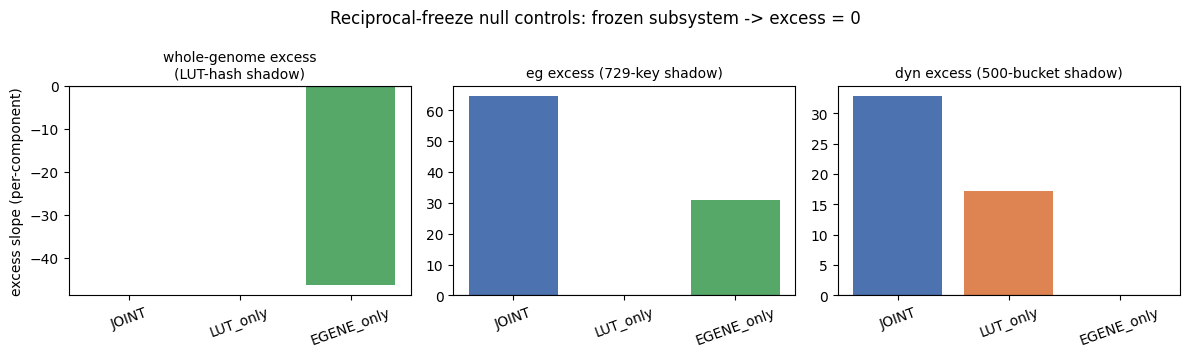

NULL CHECKS (should be ~0):
  LUT_only  eg_excess_pc_slope  = 0.0
  EGENE_only dyn_excess_pc_slope = 0.0


In [2]:
v2 = pd.read_csv(ROOT / "Research/Activity-metrics/Scans/2026-05-17_causal_control_v2/results.csv")
cols = ["excess_pc_slope", "eg_excess_pc_slope", "dyn_excess_pc_slope"]
summ = v2.groupby("arm")[cols].mean()
# order arms for readability
summ = summ.reindex(["JOINT", "LUT_only", "EGENE_only"])
display(summ.round(4))

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), sharex=True)
titles = {
    "excess_pc_slope": "whole-genome excess\n(LUT-hash shadow)",
    "eg_excess_pc_slope": "eg excess (729-key shadow)",
    "dyn_excess_pc_slope": "dyn excess (500-bucket shadow)",
}
arms = ["JOINT", "LUT_only", "EGENE_only"]
colors = ["#4C72B0", "#DD8452", "#55A868"]
for ax, col in zip(axes, cols):
    vals = [v2[v2.arm == a][col].mean() for a in arms]
    ax.bar(arms, vals, color=colors)
    ax.axhline(0, color="k", lw=0.8)
    ax.set_title(titles[col], fontsize=10)
    ax.tick_params(axis="x", rotation=20)
axes[0].set_ylabel("excess slope (per-component)")
fig.suptitle("Reciprocal-freeze null controls: frozen subsystem -> excess = 0", fontsize=12)
fig.tight_layout()
plt.show()

print("NULL CHECKS (should be ~0):")
print("  LUT_only  eg_excess_pc_slope  =", round(v2[v2.arm=="LUT_only"].eg_excess_pc_slope.mean(), 4))
print("  EGENE_only dyn_excess_pc_slope =", round(v2[v2.arm=="EGENE_only"].dyn_excess_pc_slope.mean(), 4))


### Bug 1 — LUT-only-mismatch (why v1 → v2 was necessary)

The Channon neutral shadow in `C/evoca.c` carries **LUT bytes only**, but `get_activity`
hashes the **full genome** (LUT ‖ sorted active egene bytes). So real diversity `D_G` includes
egene variation the shadow structurally cannot represent — and whole-genome
`excess_pc` is **meaningless for any egene-driven run**. The v1 EGENE_only arm exposes it: the
frozen-LUT / evolving-egene arm should have a *defined* signal, but whole-genome
`excess_pc_slope` reads ≈ −26 (consistent across seeds) — not "egene evolution fails," but the
metric being undefined. This is exactly why the fixed-space 729-key `eg` shadow was built.

In [3]:
v1 = pd.read_csv(ROOT / "Research/Activity-metrics/Scans/2026-05-16_causal_control/results.csv")
v1summ = v1.groupby("arm")[["excess_pc_slope", "excess_activity_slope"]].mean()
print("v1 (pre-fix) whole-genome excess by arm -- note the negative EGENE_only:")
display(v1summ.round(3))
print("v1 EGENE_only excess_pc_slope ~= %.1f  <-- undefined, NOT a real signal"
      % v1.query("arm=='EGENE_only'").excess_pc_slope.mean())


v1 (pre-fix) whole-genome excess by arm -- note the negative EGENE_only:


,excess_pc_slope,excess_activity_slope
arm,,
EGENE_only,-25.875,-9.129
JOINT,0.003,1.462
LUT_only,0.002,1.146


v1 EGENE_only excess_pc_slope ~= -25.9  <-- undefined, NOT a real signal


### Bug 2 — `dyn_excess_pc` frozen-rich-substrate artifact (caught by #3c)

The `dyn` shadow is *realised-flux-driven*. When `mu_lut = 0` freezes a **rich, evolved**
substrate, the realised LUT flux → 0 so the neutral baseline collapses toward 0 — while the
alive population keeps exercising the rich frozen rule. Observed/≈0 makes `dyn_excess_pc`
**explode** (#3c arm A ≈ +335, vs co-evolving arm C ≈ +1). This is *not* selection; it is an
artifact. The v2 `dyn`-null held only because it froze **GoL** (a *sparse* substrate); the null
does **not** generalise to a frozen *evolved* substrate. Rule: never interpret `dyn_excess_pc`
for an arm where the LUT is frozen on a non-trivial evolved substrate.

In [4]:
c3 = pd.read_csv(ROOT / "Research/Lineage-co-evolution/Scans/2026-05-19_3c_coevolution_substrate/results.csv")
byarm = c3.groupby("arm").agg(
    n=("arm", "size"),
    dyn_excess_pc_slope=("dyn_excess_pc_slope", "mean"),
    eg_excess_pc_slope=("eg_excess_pc_slope", "mean"),
).round(2)
display(byarm)
print("arm A (mu_lut=0 on EVOLVED substrate) dyn_excess_pc_slope ~= %.0f  <-- ARTIFACT"
      % c3.query("arm=='A'").dyn_excess_pc_slope.mean())
print("arm C (LUT co-evolving) dyn_excess_pc_slope ~= %.2f  <-- well-posed"
      % c3.query("arm=='C'").dyn_excess_pc_slope.mean())


,n,dyn_excess_pc_slope,eg_excess_pc_slope
arm,,,
A,30,335.33,-0.38
B,10,0.00,0.00
B',10,0.00,-0.00
C,30,1.01,0.24


arm A (mu_lut=0 on EVOLVED substrate) dyn_excess_pc_slope ~= 335  <-- ARTIFACT
arm C (LUT co-evolving) dyn_excess_pc_slope ~= 1.01  <-- well-posed


### Takeaways

- **The fixed-space `eg`/`dyn` shadows are the trustworthy instrument** — closed-form drift
  baselines, and they pass the reciprocal-freeze nulls exactly.
- **The whole-genome LUT-hash `excess_pc` is scope-limited** — undefined whenever egenes evolve
  (Bug 1) and turnover-fragile at high `mu_lut` (the original `neutral_apply_demography`
  no-heredity flaw, `Docs/EvoCA_research_directions.md` §2).
- **`dyn_excess_pc` is undefined on frozen evolved substrates** (Bug 2). Use the `eg`-shadow +
  lineage net-return for LUT-frozen arms.

*Sources:* `Docs/EvoCA_research_directions.md` §2; `Research/Activity-metrics/Scans/2026-05-16_causal_control/`,
`Research/Activity-metrics/Scans/2026-05-17_causal_control_v2/`; `Research/Lineage-co-evolution/Scans/2026-05-19_3c_coevolution_substrate/`; project
memories `shadow-models-lut-only-mismatch`, `dyn-shadow-frozen-rich-substrate`.